# 3. Neural fields: bumps and fronts (Chapter 8)
Amari's equation $\partial_t u = -u + \int w(x-y)f(u(y))\,dy + I$ on a ring of 240 points, using XPP's `conv` special.

**Picture first:** a bump of width $a$ survives if the input at its edge, $W(a) = \int_0^a w$, equals the threshold.

In [1]:
import numpy as np, matplotlib.pyplot as plt, pyxpp
plt.rcParams.update({"figure.figsize": (7, 4.2), "axes.spines.top": False, "axes.spines.right": False})
def load(name, **pars):
    m = pyxpp.load(text=open(f"ode/{name}.ode").read())
    if pars: m.set(**pars)
    return m

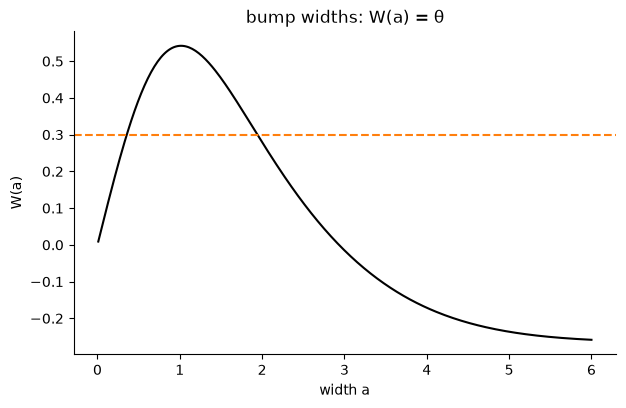

In [2]:
from scipy.integrate import quad
w = lambda x: 1.5*np.exp(-x**2) - 0.6*np.exp(-(x/3)**2)
d = np.linspace(0.01, 6, 300); W = [quad(w, 0, x)[0] for x in d]
plt.plot(d, W, 'k'); plt.axhline(0.3, color='C1', ls='--'); plt.xlabel('width a'); plt.ylabel('W(a)'); plt.title('bump widths: W(a) = θ');

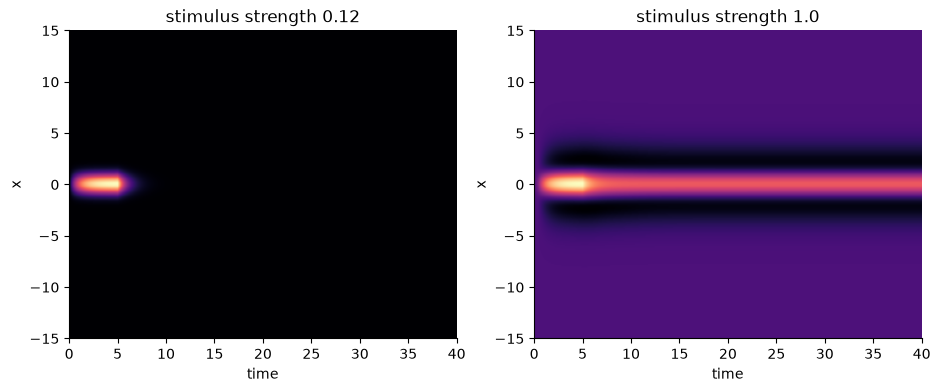

In [3]:
m = load('amari_bump')
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, s in zip(axs, [0.12, 1.0]):
    m.set(s=s); tr = m.run(total=40)
    U = np.array([tr[f'u{j}'] for j in range(240)])
    ax.imshow(U, aspect='auto', origin='lower', extent=[0, 40, -15, 15], cmap='magma'); ax.set_title(f'stimulus strength {s}')
    ax.set_xlabel('time'); ax.set_ylabel('x')

Weak stimulus: the field returns to rest. Strong: a bump persists after the stimulus stops at $t = 5$ (a memory of position).

**Try:** raise `th` towards the maximum of $W$; when does the bump stop existing?